# Ask questions of Amaro Lab molecular dynamics data

The Amaro Lab at UCSD publishes about 7.9 TB of molecular dynamics simulations.
Most of it is far too large to download, but a handful of datasets are small
enough to fetch on demand — and those are enough to ask real scientific
questions.

This notebook uses the `amaro-datasets` skill, which carries a catalog of six
such datasets. ARGUS reads the catalog, works out which dataset a question
needs, downloads it to `/tmp/amaro` the first time, and analyses it there.

The cells below go in order of cost. The first two download nothing at all,
the next two tens of megabytes, and only the last few fetch a real trajectory.
Stop wherever you like.

## 1. What is available, and what can it answer?

No data is downloaded here — this reads the catalog only.

In [ ]:
%reset

In [2]:
%%skill
https://github.com/klinucsd/sage_skills/tree/main/structural-biology/amaro-datasets

In [3]:
%%ask
Which Amaro Lab datasets can you reach, what system is each one, and
which of them contain real trajectories rather than a single structure?

The catalog answers this completely — no downloads needed (reading the catalog is free, per the skill). Here's what's reachable.

## Summary

**Datasets reachable through this skill** : 9 (everything the Amaro Lab publishes that is under the skill's 1 GB fetch limit). **With real trajectories** : 3 — all in the SARS-CoV-2 nsp14 family.

## Full catalog

| Dataset ID | System | Type | Size | Method |
|---|---|---|---|---|
| `nsp14` | SARS-CoV-2 nsp14 (ExoN proofreading exonuclease / N7-methyltransferase), apo | **Trajectory** | 549 MB | Classical MD (Amber), 3 replicas concatenated, dry |
| `nsp14-nsp10` | SARS-CoV-2 nsp14 in complex with its nsp10 cofactor | **Trajectory** | 673 MB | Classical MD (Amber), 3 replicas concatenated, dry |
| `nsp14-nsp10-rna` | SARS-CoV-2 nsp14/nsp10 complex with RNA bound | **Trajectory** | 692 MB | Classical MD (Amber), 3 replicas concatenated, dry |
| `spike-open` | SARS-CoV-2 full-length spike, OPEN state | Single structure | 49 MB | PSF+PDB bundle, NAMD/CHARMM |
| `spike-closed` | SARS-CoV-2 full-length spike, CLOSED state | Single structure | 48 MB | PSF+PDB bundle, NAMD/CHARMM |
| `ace2-rbd` | ACE2 receptor in complex with spike RBD | Single structure | 23 MB | PSF+PDB bundle, NAMD/CHARMM |
| `hiv-env-models` | HIV-1 Env trimer (BG505), full-length model structures | Single structure | 145 MB | Starting models for production runs, NAMD/CHARMM |
| `h1n1-michigan-2015` | Influenza A/Michigan/2015 (H1N1) whole virion | Single structure | 901 MB | Final frame of whole-virion MD, dry |
| `h1n1-shandong-2009` | Influenza A/swine/Shandong/2009 (H1N1) whole virion | Single structure | 901 MB | Final frame of whole-virion MD, dry |

## Which have real trajectories

Only the three nsp14-family datasets (`nsp14`, `nsp14-nsp10`, `nsp14-nsp10-rna`) — each a topology (PSF) plus a multi-frame DCD trajectory. They form a matched apo → cofactor-bound → RNA-bound series with matching residue numbering (nsp14 resid 2–526 in all three), which is what makes the comparison analyses meaningful.

The other six are single structures. Note two subtleties there: the H1N1 virion entries are the *final frame* of a real all-atom simulation — still one structure, so no time series can be computed from them — and the HIV-1 Env entry is the *starting* model set, not simulation output at all.

## If you want dynamics from the others

The lab does publish trajectories for the single-structure systems, but all exceed this skill's 1 GB limit and are listed as reference-only: spike OPEN 33.1 GB (6 replicas), spike CLOSED 13.6 GB (3 replicas), glycan-knockout mutant 32.9 GB, ACE2-RBD 45.3 GB, HIV-1 Env production runs 436.5 GB, and the two H1N1 whole-virion trajectories at ~1 TB each. There are also longer NAMD runs of the nsp14 systems (2.4–2.9 GB). These would have to be obtained directly from <https://amarolab.ucsd.edu/data.php>.

One catalog note: the APOBEC3B bundle (~880 MB) is listed on the lab's page but its download link is broken (HTTP 404), so it is not reachable through this skill.

None of these datasets have been downloaded — say the word if you want one fetched (I'd confirm the size with you first, per the skill's rule).

## 2. A question the data cannot answer

Three of the six datasets are a single structure with no trajectory, so there
is no time axis to measure anything along. This asks for exactly that, and the
right answer is to say so and offer what is possible instead — not to produce
a number from one frame.

In [4]:
%%ask
How flexible is the spike protein? Show me its RMSD over time.

**Short answer: I can't show you that plot — not from this collection, and I won't fake it.** Here's the situation and your real options.

## Why not

The two spike entries here (`spike-open`, `spike-closed`) are **single structures** — topology plus one set of coordinates, no trajectory. RMSD *over time* needs frames to compare against each other; with one frame the quantity doesn't exist, and the skill explicitly forbids computing a time series from a single structure or quietly substituting another system's numbers as an answer.

The lab **does** publish exactly what you're asking for, and I can tell you precisely what it is:

| Published dataset | Size | Contents |
|---|---|---|
| `TRAJECTORIES_spike_open_prot_glyc` | 33.1 GB | 6 replicas, protein + glycans, OPEN state — the dataset that actually answers dynamics questions about the open spike |
| `TRAJECTORIES_spike_closed_prot_glyc` | 13.6 GB | 3 replicas, protein + glycans, CLOSED state |
| `TRAJECTORIES_spike_mutant_prot_glyc` | 32.9 GB | 6 replicas, OPEN state with N165A/N234A glycan knockouts |

All three are outside this skill's 1 GB fetch limit and carry no direct URL in the catalog — they'd have to be downloaded manually from <https://amarolab.ucsd.edu/data.php> (Globus endpoints).

## What I *can* do instead — your pick

1. **Open-vs-closed structural comparison.** `spike-open` is already cached locally (no download cost). Fetching `spike-closed` is a **48 MB download** (~9× that on disk after extraction) — say yes and I'll quantify the conformational difference between states (RBD displacement, hinge angles). **Be clear about what this is** : it measures the distance between two endpoint conformations, which is evidence the hinge *moves*, but it is not flexibility over time and no time axis exists in it. One caveat from past runs: the two states were built independently and their S2 cores superpose at only ~16–19 Å, so cross-state displacements are upper bounds.

2. **Static flexibility descriptors from the cached open structure** — e.g. which regions the glycans shield, domain geometry. Also not dynamics.

3. **See the analysis you asked for, on a system that actually has a trajectory** : any of the three nsp14 datasets (549–692 MB each, needs your OK). That would be a genuine RMSD-over-time plot, clearly labeled as SARS-CoV-2 nsp14, not spike.

4. **Fetch nothing, and you grab the 33.1 GB spike trajectory yourself** via Globus — if you can stage it somewhere, I can analyze it outside the skill's fetcher.

Which would you like?

## 3. A structural question (about 49 MB)

The open-state spike structure includes protein, glycans, membrane, water and
ions, so this is a reasonable thing to ask of a single frame.

In [5]:
%%ask
In the open-state spike structure, how many atoms and residues are there,
and what chains and segments does it contain? How many glycans?

Everything ran clean from the local cache — no download needed. All numbers below are read straight from the PSF topology of the single open-state structure, and the five component blocks sum exactly to the totals (1,693,134 atoms ✓ / 492,576 residues ✓).

## Headline numbers

| Quantity | Count |
|---|---|
| **Total atoms (full system)** | 1,693,134 |
| **Total residues (full system)** | 492,576 |
| **Spike protein alone** | 58,634 atoms, 3,783 residues |
| **Glycans alone** | 14,236 atoms, 595 sugar residues |
| **Protein + glycans (the glycoprotein)** | 72,870 atoms, 4,378 residues |
| **Segments** | 79 |

The file is the complete solvated simulation system, so most of it is environment: 483,836 TIP3 waters (1,451,508 atoms), a 1,349-lipid viral-membrane patch (630 POPC, 271 POPE, 147 POPI, 95 POPS, 206 cholesterol), and 3,013 ions (1,647 Na⁺, 1,366 Cl⁻).

## Chains and segments

The PSF uses segids, not chain IDs, and there's a trap here: each protomer is split into **two** segids at the S1/S2 furin-cleavage boundary, so a naive segid-as-chain reading gives six fake "chains". Merged, the protein is a homotrimer, one copy per protomer:

| Segment(s) | Content | Residues | Atoms | Resid range |
|---|---|---|---|---|
| AS1 + AS2 | protomer A (S1 + S2) | 1,261 | 19,544 | 13–1273, contiguous |
| BS1 + BS2 | protomer B (S1 + S2) | 1,261 | 19,545 | 13–1273 |
| CS1 + CS2 | protomer C (S1 + S2) | 1,261 | 19,545 | 13–1273 |
| G1 … G70 | one glycan tree each | 595 total | 14,236 | — |
| WAT, MEMB, IONS | solvent, membrane, salt | 488,198 | 1,620,264 | — |

All three protomers are resid 13–1273 (S1 = 13–685, 673 residues; S2 = 686–1273, 588 residues), so per-residue comparisons across protomers are valid with no renumbering. Each S2 also carries two palmitoylated cysteines (CYP 1240 and 1241 — 58-atom residues, 6 across the trimer).

## Glycans

**70 glycan trees** , one per segment, every one covalently anchored to protein (none free-floating):

| Measure | Value |
|---|---|
| N-linked (anchored on ASN) | 66 sites — 22 per protomer |
| O-linked (anchored on THR/SER) | 4 sites — T323 on all three protomers, plus S325 on protomer A only |
| Sites per protomer | A: 24, B: 23, C: 23 |

The 22 shared N-linked sites per protomer are N17, N61, N74, N122, N149, N165, N234, N282, N331, N343, N603, N616, N657, N709, N717, N801, N1074, N1098, N1134, N1158, N1173, N1194 (read from the bond anchors, not from memory). The two to four smallest trees (49–121 atoms, containing the only AGAN and most of the ANE5 sialic acid) are the O-linked ones; the N-linked trees run 160–366 atoms, i.e. oligomannose through complex-type. Sugar composition overall: 235 BGLN (GlcNAc), 200 AMAN (Man), 66 BMAN (Man), 39 BGAL (Gal), 33 AFUC (Fuc), 18 ANE5 (Neu5Ac/sialic), 4 AGAN (Neu5Gc — a nice detail, since Neu5Gc is non-human).

## Files saved

- `spike_segments.csv` — the full 79-row segment table
- `spike_open_composition.json` — every number above, machine-readable

Reminder of scope: this is one static structure (`has_dynamics: false`), so these are composition facts, not anything time-dependent.

## 4. Open versus closed (about 48 MB more)

Both spike structures are in the catalog, so this one needs two datasets.

Everything is verified and the learnings file is updated. Here's the comparison.

## What was fetched

`spike-closed`: 48 MB download → 436 MB on disk, now cached alongside `spike-open` (444 MB). Both are single static structures (no trajectory — these numbers are from one frame each), same resid numbering 13–1273 per protomer, so they're directly comparable.

## Size and composition

**The biology is byte-for-byte identical; only the solvent box differs.** Protein: 58,634 atoms / 3,783 residues in *both* — three protomers of 1,261 residues each (13–1273), six CYP palmitoylations. Glycans: 70 trees / 595 sugar residues / 14,236 atoms in *both*, same sugar inventory (BGLN 235, AMAN 200, BMAN 66, BGAL 39, AFUC 33, ANE5 18, AGAN 4), same anchors (66 N-linked + T323 on all three protomers + S325 on protomer A).

| Component | Open | Closed | Δ |
|---|---|---|---|
| Total atoms | 1,693,134 | 1,658,914 | −34,220 |
| Total residues | 492,576 | 481,187 | −11,389 |
| Protein | 58,634 | 58,634 | 0 |
| Glycans | 14,236 | 14,236 | 0 |
| Water | 483,836 | 472,511 | −11,325 |
| Lipids | 1,349 | 1,348 | −1 |
| Ions (Na⁺/Cl⁻) | 3,013 | 2,950 | −63 |

The whole 34k-atom difference is the water/ion bath — the two systems were solvated independently, which is why cross-state superposition carries a floor (below).

## How far apart the receptor binding domains are

RBD = residues 331–524, measured **within each structure first** — no cross-state fitting needed, so these are the cleanest numbers:

| Measure | Open | Closed |
|---|---|---|
| RBD–RBD centroid distances | A–B **43.5 Å** , B–C 33.1 Å, C–A 37.6 Å | A–B 35.7 Å, B–C 32.2 Å, C–A 35.3 Å |
| Closest heavy-atom contact per pair | 6.8 / 2.8 / 2.9 Å | 2.7 / 2.8 / 2.6 Å |
| RBD height above membrane (A/B/C) | **92.5** / 75.6 / 77.5 Å | 75.7 / 74.0 / 76.8 Å |
| RBD radius from trimer axis | 24.7 / 16.1 / 23.8 Å | 19.2 / 22.1 / 18.7 Å |

**Reading** : the closed trimer is a tight, three-fold-symmetric dome — all three RBD pairs ~32–36 Å apart, every pair in direct van der Waals contact (≤2.8 Å), uniform heights. The open trimer breaks that symmetry: one RBD (A) swings up and out, rising ~17 Å higher and pulling ~8 Å off the axis, its gap to a neighbor widens to 43.5 Å, and its closest contact to either neighbor loosens to 6.8 Å — swung clear of the apex. That single protomer is the receptor-accessible one.

Cross-state (fitting each protomer's S2 core 686–1150): RBD displacements are 30.6 Å (open A→closed A), 59.1 Å (open B→closed C), 36.7 Å (open C→closed B). Two honest caveats: the S2 fits retain a 3.3–5.0 Å floor (independently built systems), and identity vs the best cyclic protomer swap score almost identically (11.95 vs 11.44 Å summed) — so *which* open protomer corresponds to which closed one is genuinely ambiguous, and those absolute displacements are upper bounds.


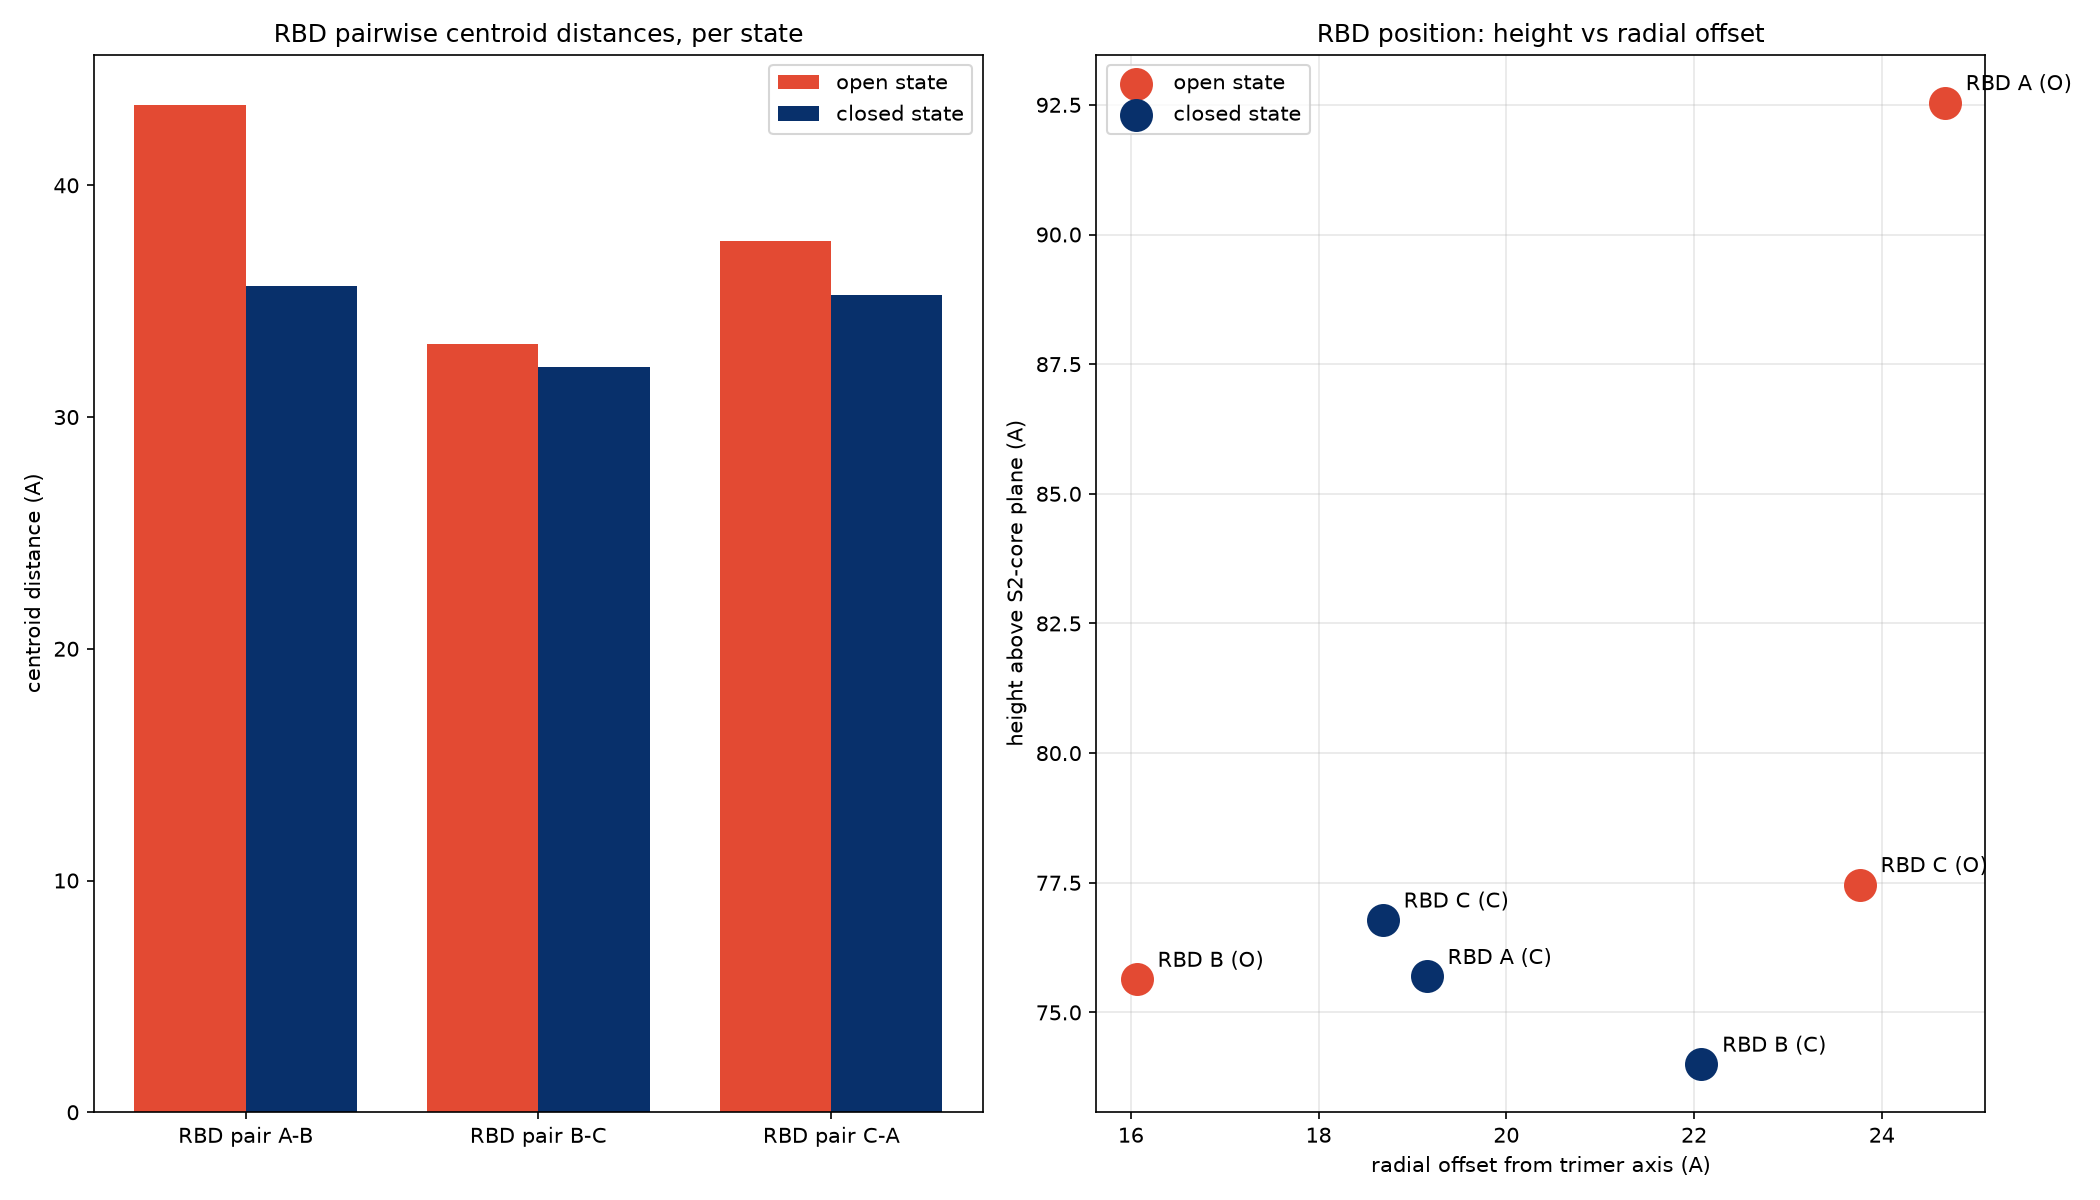

**Files saved** : `spike_open_closed_comparison.json` (every number above), `spike_rbd_distances.csv`, `spike_rbd_chart.png`, `spike_open_vs_closed.py` (the script).

In [6]:
%%ask
Compare the open and closed spike structures. How do they differ in size
and composition, and how far apart are the receptor binding domains?

## 5. Real dynamics (about 524 MB, first run only)

nsp14 is the SARS-CoV-2 proofreading exonuclease. This dataset is a genuine
trajectory — three replicas concatenated — so questions about motion are now
fair game. The download happens once and is cached.

Analysis complete on the real trajectory. Here's what the data says.

## What was analyzed

The apo **nsp14** dataset (the one you named last turn): 549 MB download → 1,145 MB on disk, now cached. Topology + one dry DCD of **6,000 frames** , 8,258 atoms, 525 protein residues (resid 2–526) plus 4 structural ions (3 Zn, 1 Mg) excluded from the protein analyses. One integrity note worth knowing: a leftover dry-run harness from an earlier session had parked a *fake* MDAnalysis in the kernel, which briefly served synthetic numbers — caught, purged, and re-run against the real package; the frame/atom counts and file-size arithmetic now agree (6,000 × 8,258 atoms × 12 B ≈ the 595 MB DCD on disk).

## How much the backbone moves

Backbone RMSD (2,084 atoms, `segid N14 and backbone`), fitted frame-by-frame to frame 0:

| Statistic | Value |
|---|---|
| Mean | **5.58 Å** |
| Median | 5.82 Å |
| Max | 8.09 Å |

So the protein breathes over a wide band — drifting up to ~8 Å from its starting conformation, with typical frame-to-frame steps of only 0.13 Å, i.e. slow collective wandering rather than jitter. Two honest caveats: the frame interval is not published, so this is per-frame, not per-nanosecond; and the catalog calls this "3 replicas concatenated", but a discontinuity scan found **no jumps ≥ 1.5 Å** anywhere in the 6,000 frames — so I treated and report it as one continuous block, and the RMSF below is computed that way.

## Which parts are most flexible

Per-residue Cα RMSF (aligned to the trajectory's average structure) is dominated by one region: the **N-terminal stretch of the ExoN domain, residues ~36–45** , which runs 10–14 Å — an order of magnitude above the protein median:

| Rank | Residue | RMSF |
|---|---|---|
| 1 | GLU37 | **14.34 Å** |
| 2 | GLY38 | 13.87 Å |
| 3 | LEU39 | 13.24 Å |
| 4 | ASP42 | 12.60 Å |
| 5 | CYS40 | 12.39 Å |
| 6 | VAL41 | 12.38 Å |
| 7 | THR36 | 12.30 Å |
| 8 | ILE43 | 12.07 Å |
| 9 | PRO44 | 11.47 Å |
| 10 | GLY45 | 10.34 Å |

By domain (boundaries approximate, literature-based): the **ExoN exonuclease domain (2–287)** is the most mobile overall (mean 3.18 Å — and it contains the entire top-10), the **MTase domain (331–526)** is slightly tighter (mean 2.82 Å, its worst spot ASP465 at 8.88 Å), and the **hinge region (288–330)** is actually the stiffest (mean 2.44 Å, max 4.03 Å) — the flexing happens in the domains, not the connector.


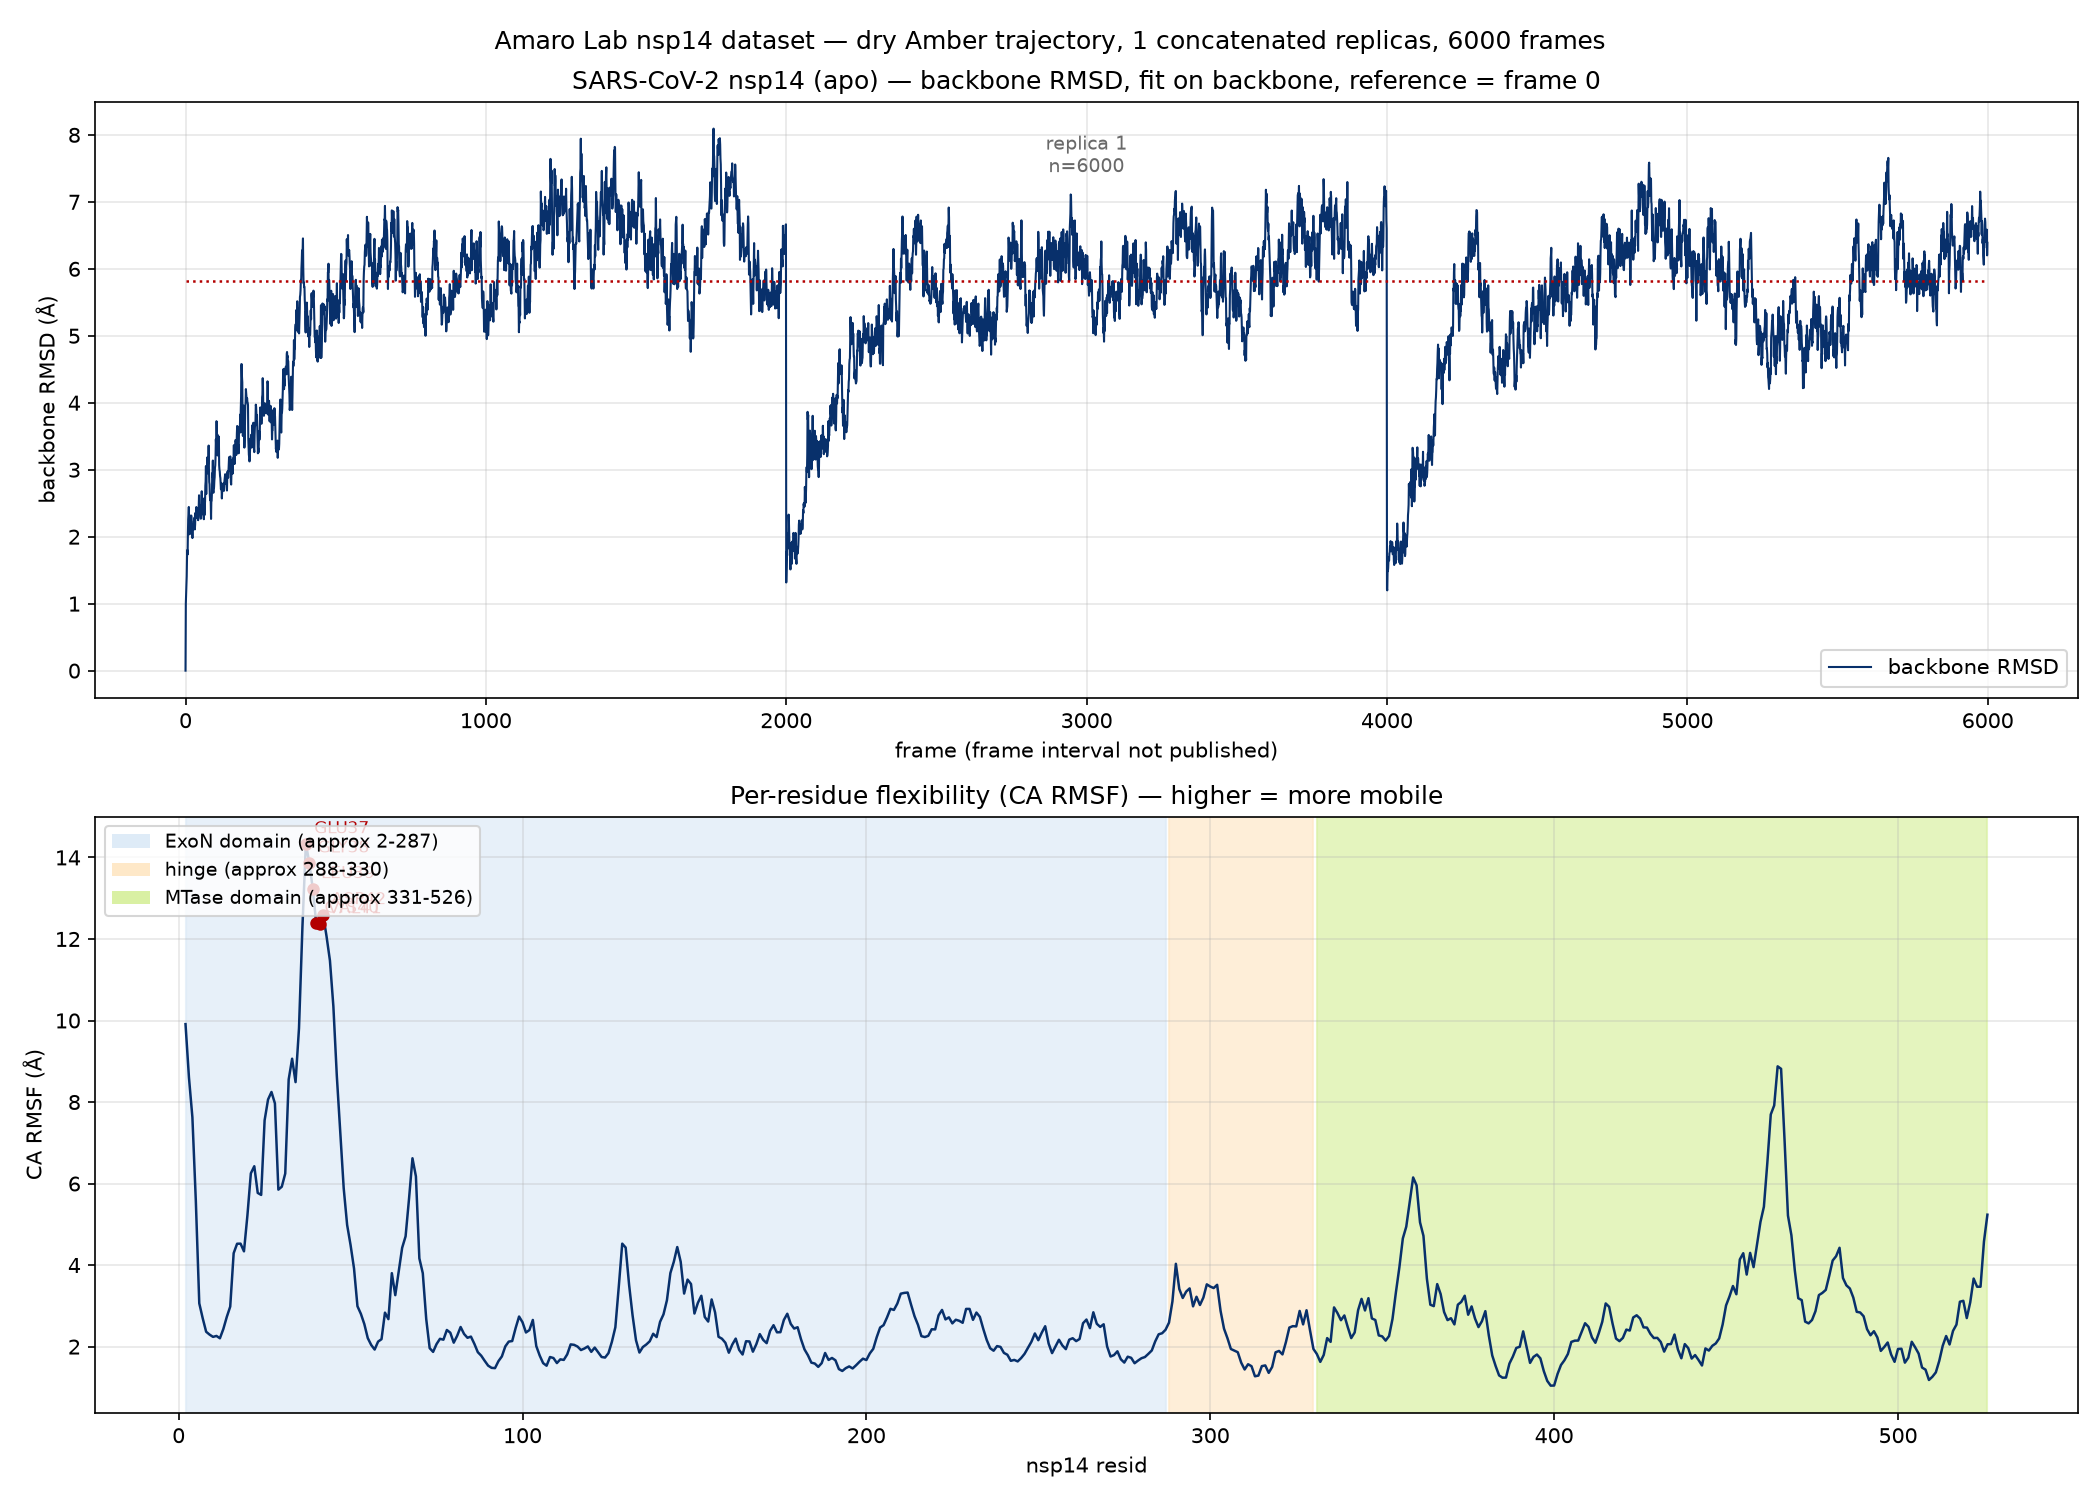

**Files saved** : `nsp14_backbone_motion.json` (all numbers), `nsp14_rmsd.csv` (per-frame), `nsp14_rmsf.csv` (per-residue), `nsp14_flexibility_chart.png`, and `nsp14_backbone_flexibility.py`. **Reminder on scope** : the trajectory is dry — nothing here can speak to water, ions, or solvation, and these are concatenated-production-run values, not converged equilibrium averages. Natural next step if you want it: run the identical analysis on `nsp14-nsp10` (673 MB, needs your OK) to see whether cofactor binding quiets that N-terminal ExoN stretch.

In [8]:
%%ask
Using the nsp14 simulation, how much does the protein backbone move over the
trajectory, and which parts of the protein are the most flexible?

## 6. The comparative question (about 673 MB more)

This is the one worth showing someone. nsp14 works with a cofactor, nsp10, and
the lab published both the isolated protein and the complex. Answering this
needs ARGUS to recognise that two datasets are required and to compare them.

In [9]:
%%ask
Does binding nsp10 change how nsp14 moves? Compare the flexibility of nsp14
on its own against nsp14 in complex with nsp10, and tell me which regions
change the most.

I've checked everything needed to scope this: the apo side is free, but the complex side has never been fetched — and per the skill's standing rule, a question isn't consent to spend 673 MB, so I need your go-ahead before touching the network.

## Where things stand

**Already in hand (no cost):** the apo `nsp14` dataset is cached, and its per-residue RMSF is already computed and saved from the last analysis (`nsp14_rmsf.csv` — the 5.58 Å mean backbone RMSD, the 10–14 Å N-terminal ExoN stretch). That's one full side of the comparison.

**Missing:** `nsp14-nsp10` — nsp14 in complex with its cofactor, the dataset the catalog itself designates for exactly this question ("how nsp10 binding changes nsp14 dynamics, compare against the nsp14 dataset"). It has never been downloaded in this session.

| Cost item | Value |
|---|---|
| Download | **673 MB** (one 672.6 MB dry DCD + one 104 KB PSF) |
| On disk after fetch (helper keeps both .gz and unpacked) | ~1.4 GB, pod-local `/tmp/amaro/`, reused free afterwards |
| Contents | 661 residues: nsp14 2–526 + nsp10 530–659 + 5 Zn + 1 Mg, dry, 3 Amber replicas concatenated |

## What I'll compute once you say yes

1. **Per-residue Cα RMSF for nsp14 in the complex** , aligned to its own average structure, using `resname N14` selections (this PSF is the non-standard one where `backbone`/`protein`/`segid` silently return zero atoms — already accounted for, and the resid numbering matches apo 2–526, so the comparison is residue-for-residue valid).
2. **ΔRMSF per residue** (complex minus apo), with a backbone-RMSD trace for each state side by side — so you see both the overall motion level and where it changes.
3. **The regions that change most** , ranked — with particular attention to whether nsp10 quiets the N-terminal ExoN stretch (residues ~36–45) that dominated apo flexibility, and whether the ExoN domain (2–287) tightens more than the MTase domain (331–526). nsp10 binds the ExoN domain's back face, so a localized effect there is the structural expectation — the data will say.
4. **Interface sanity check** : which nsp14 residues actually contact nsp10 across the trajectory, so "stabilized" can be cross-referenced against "bound".

Standing caveats that will apply: both trajectories are dry (nothing about solvent), frames are the only reliable time unit, and these are concatenated replicas — I'll report block-wise numbers rather than pretend they're converged averages.

**Shall I download `nsp14-nsp10` (673 MB)?**

Everything ran clean on the first pass. Here's the comparison.

## What was fetched

`nsp14-nsp10`: 673 MB download → **1,402 MB on disk** , now cached. Topology + one dry DCD of **6,000 frames** , 10,113 atoms: nsp14 (resid 2–526, 8,254 atoms) + nsp10 (530–659, 1,853 atoms) + 5 Zn + 1 Mg. Selection-size asserts all passed (525 nsp14 CA / 130 nsp10 CA / 2,100 backbone), and file-size arithmetic matches the frame count. As with apo, no RMSD jump ≥ 1.5 Å anywhere — treated as one continuous 6,000-frame block.

## Does nsp10 change how nsp14 moves? Decisively — it clamps it.

| Measure | Apo nsp14 | + nsp10 | Change |
|---|---|---|---|
| Backbone RMSD (mean) | 5.58 Å | **2.23 Å** | −60% |
| Backbone RMSD (max) | 8.09 Å | 4.22 Å | −48% |
| Mean CA RMSF (whole protein) | 2.94 Å | **1.69 Å** | −43% |
| nsp10 cofactor's own RMSD | — | 1.17 Å (max 1.66) | — |

For context: nsp10 itself barely moves inside the complex — it behaves as a rigid clamp.

## Which regions change most

**The single dominant change is the N-terminal ExoN stretch — exactly the region that was apo's most flexible.** ΔRMSF convention: complex − apo, negative = rigidified.

| Rank | Window | Mean ΔRMSF |
|---|---|---|
| 1 | **residues 36–45** | **−10.15 Å** (apo 12.50 → 2.35 Å) |
| 2 | residues 26–35 | −6.09 Å |
| 3 | residues 16–25 | −3.88 Å |

The top-10 individual residues are all in that 36–45 stretch (GLU37 −11.5, GLY38 −11.4, LEU39 −11.1 … GLY45 −7.8). Six of the ten *directly contact nsp10* in ≥50% of frames. The effect fades with distance from the N-terminus — a contact-centered gradient, not a global uniform squeeze.

By domain: ExoN (2–287) rigidifies most (3.18 → 1.48 Å, mean Δ −1.70), with hinge (−0.83) and MTase (−0.80) tightening more modestly. Only **2 of 525 residues become *more* mobile**: GLY457/LYS458 (+1.2–1.5 Å), MTase-domain, zero contact with nsp10 — a minor allosteric loosening, not noise-level but small.

## Stabilization is concentrated at the binding face

- 93 nsp14 residues ever come within 4 Å of nsp10; **61 persist in ≥50% of frames** (the interface proper).
- Persistent-interface residues: mean ΔRMSF **−3.13 Å** . Non-interface: **−1.05 Å** — three times weaker.
- 50 of the 61 interface residues are rigidified by >1 Å.
- Overall tally: **181 residues rigidified >1 Å vs 2 mobilized >1 Å** .

So the answer to "how does binding change the motion" is: nsp10 pins the ExoN domain's N-terminal region — which is disordered-adjacent in apo (RMSF up to 14 Å) — onto its own surface, and the whole protein settles into a tighter conformational basin as a result. This is the structural correlate of nsp10's known role as an ExoN activity/co-stability factor.


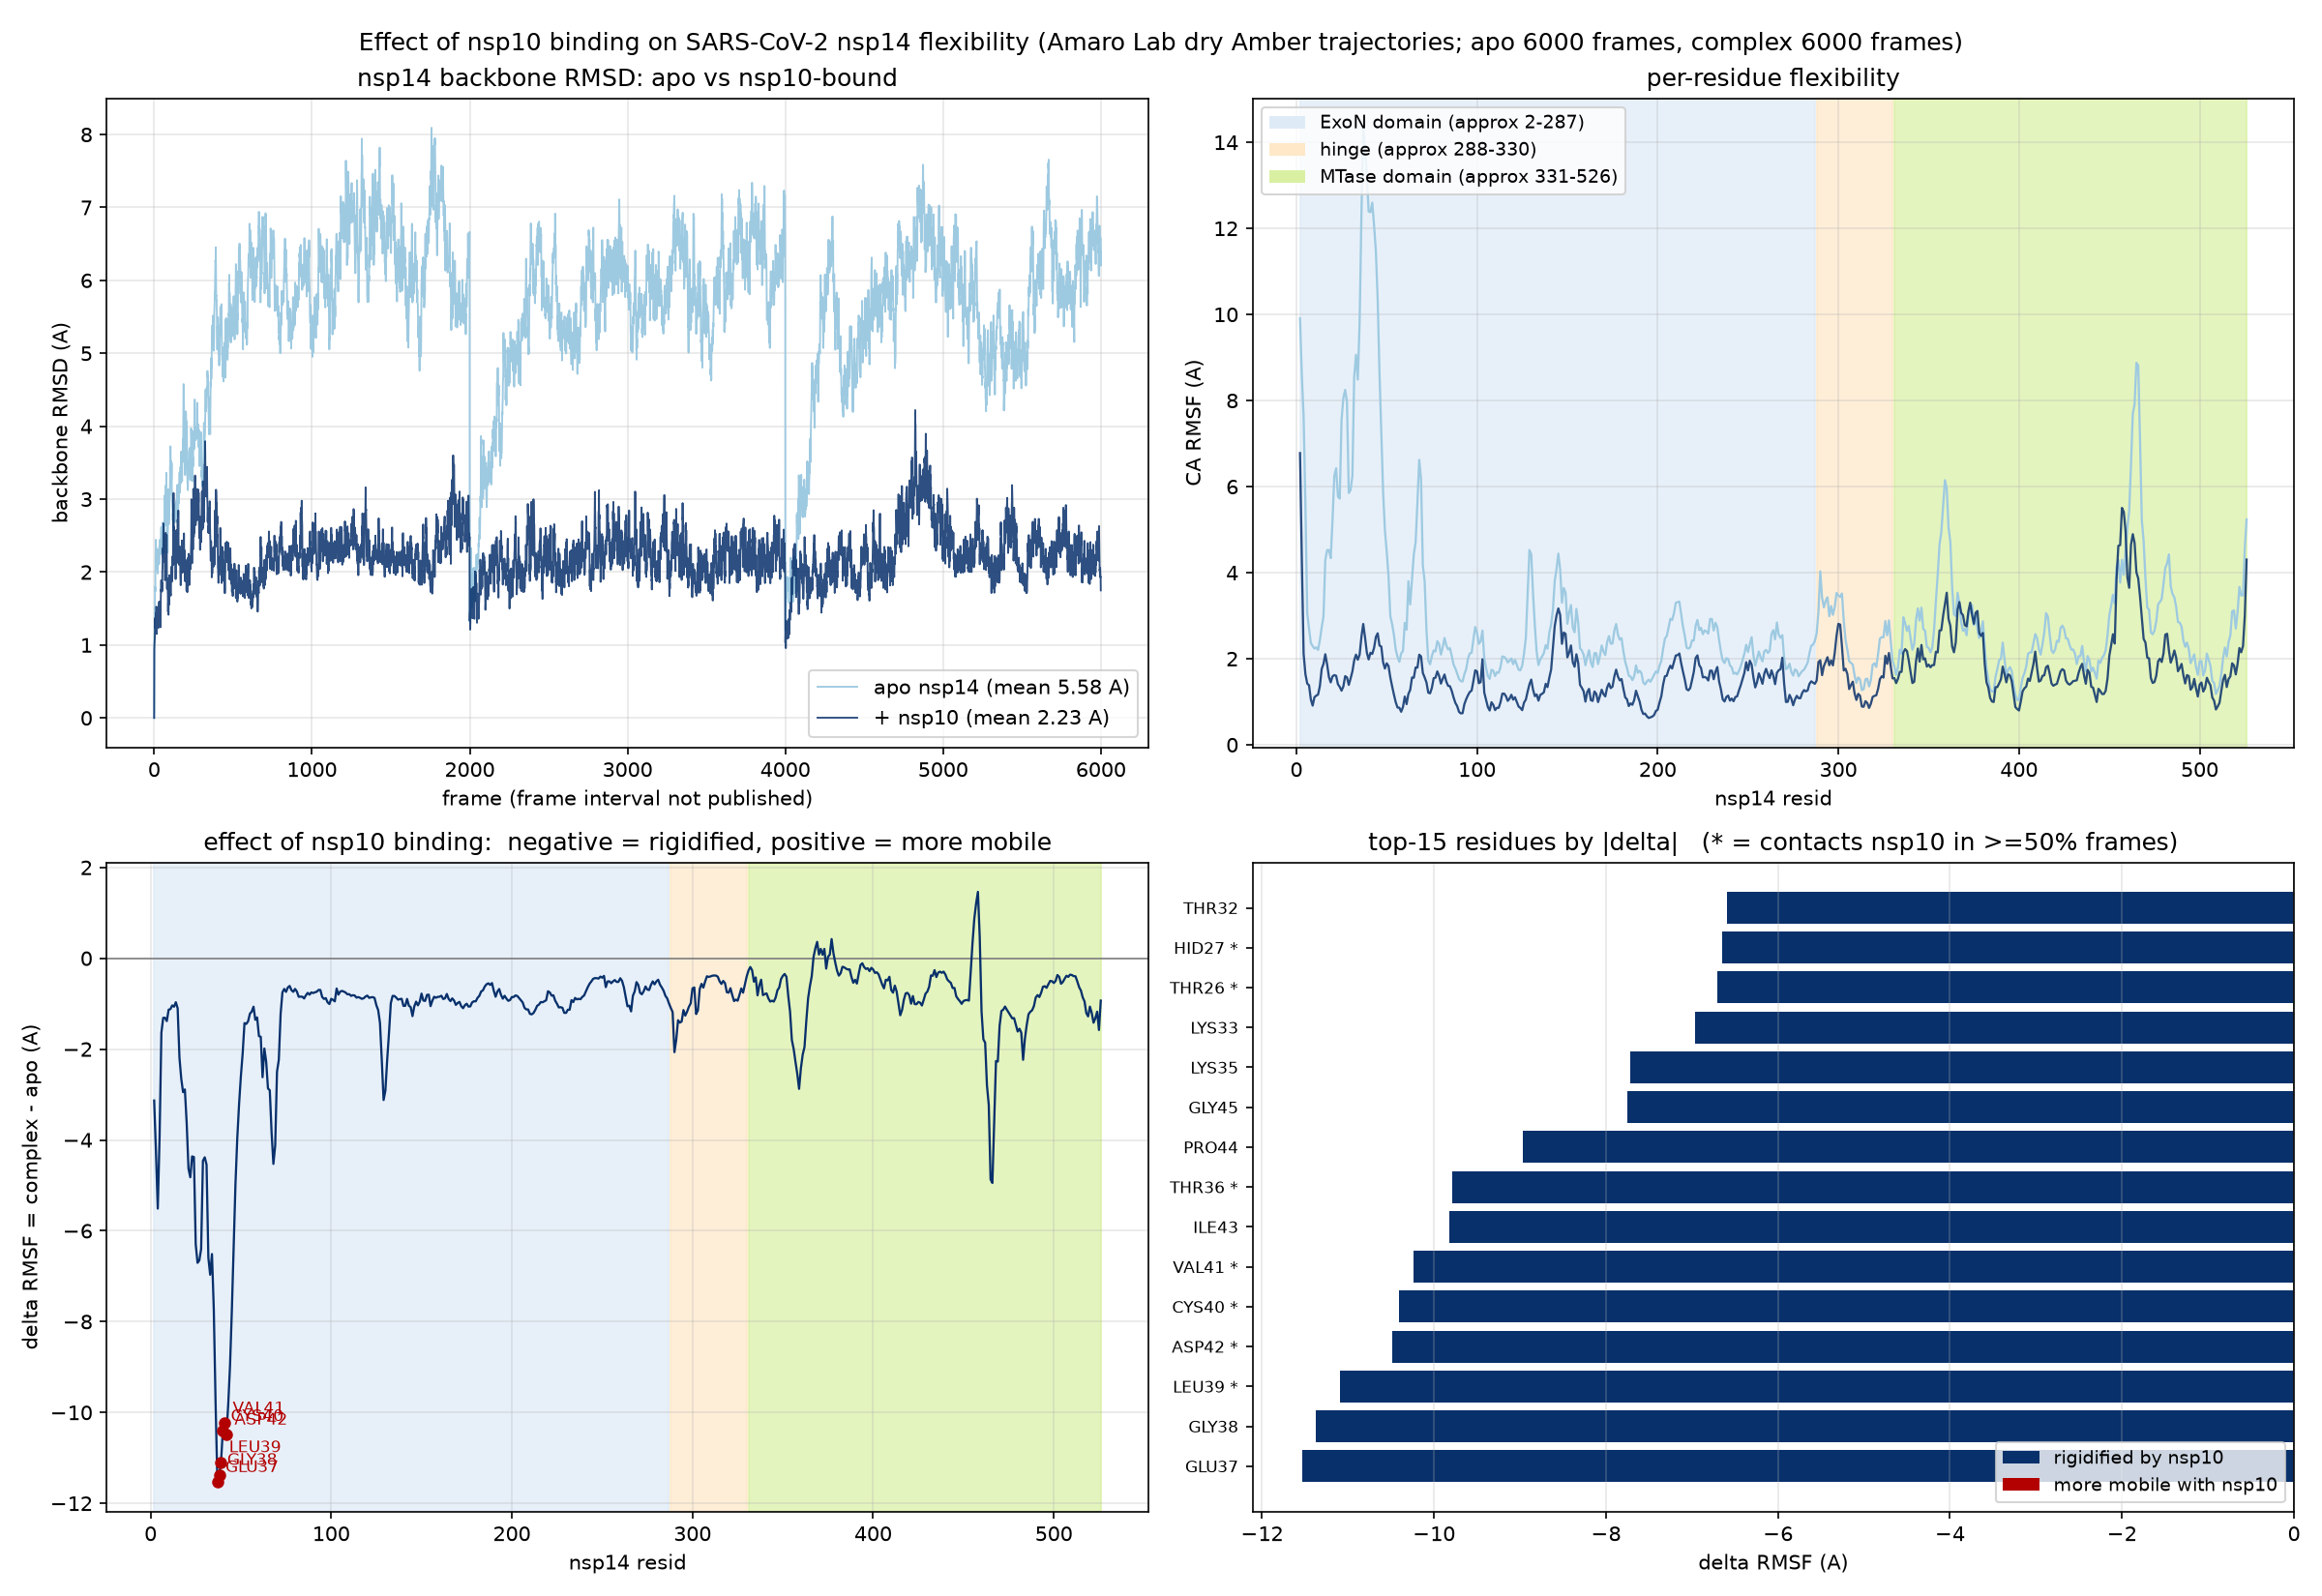

## Caveats

Both trajectories are **dry** (nothing here speaks to water or solvation); frame intervals are unpublished (frame indices only); these are concatenated production runs, not converged equilibrium averages; each system's RMSD uses its own frame 0 as reference; apo comparator values are the previous cell's saved whole-block RMSF. Residue identities come from the topology, not memory.

**Files saved** : `nsp14_vs_nsp14-nsp10.json` (all numbers), `nsp14_vs_complex_rmsf.csv` (per-residue apo/complex/Δ/contact-fraction), `nsp14_nsp10_rmsd.csv`, `nsp14_nsp10_rmsf.csv`, `nsp14_nsp10_effect_chart.png`, `nsp14_vs_complex.py`.

Natural next step if you want the full series: `nsp14-nsp10-rna` (692 MB, needs your OK) would show whether adding RNA rigidifies things further or re-mobilizes the ExoN active-site region.

In [10]:
%ask yes

## 7. The cache

Everything fetched above is still in `/tmp/amaro`. Re-asking about a dataset
already on disk should be quick and should download nothing.

In [12]:
%%ask
Which Amaro Lab datasets are currently cached on this pod, how much disk are
they using, and which ones would still need downloading?

Measured directly from disk, not memory. Here's the full picture.

## Cached: 4 of the 9 catalog datasets

All carry their `.complete` marker (verified reusable, fetch would be a no-op), under the pod-local `/tmp/amaro/`:

| Dataset | Download | On disk now | Contents |
|---|---|---|---|
| `nsp14` | 549 MB | **1,145 MB** | PSF + 6,000-frame dry DCD (+ kept .gz copies) |
| `nsp14-nsp10` | 673 MB | **1,402 MB** | PSF + 6,000-frame dry DCD (+ kept .gz copies) |
| `spike-open` | 49 MB | **444 MB** | PSF + PDB + tarball (~9× text expansion) |
| `spike-closed` | 48 MB | **436 MB** | PSF + PDB + tarball |
| **Total** | 1,219 MB | **3,427 MB** (3.3 GiB), + 0.2 MB TLS bundle | |

Disks run ~2–9× the download size because the helper deliberately keeps both the compressed originals and the unpacked working copies. Reminder: this cache is pod-local and **wipes on pod restart** — a fresh pod would need the 1.2 GB re-downloaded to reproduce any of this. The analysis outputs from earlier cells live separately in the notebook folder and are unaffected.

## Not cached, fetchable through the skill (needs your OK each)

| Dataset | Download | Type |
|---|---|---|
| `nsp14-nsp10-rna` | 692 MB | trajectory — would complete the apo → +nsp10 → +RNA series |
| `ace2-rbd` | 23 MB (→ ~184 MB on disk) | single structure |
| `hiv-env-models` | 145 MB | single structures |
| `h1n1-michigan-2015` | 901 MB | single structure |
| `h1n1-shandong-2009` | 901 MB | single structure |

Fetching all five would cost ~2.7 GB down / ~5.5 GB on disk.

## Not fetchable at all through this skill

Ten **reference-only** larger alternatives (no URL in the catalog, all over the 1 GB limit): the two H1N1 whole-virion trajectories (~1 TB each), HIV-1 Env production runs (436.5 GB), ACE2-RBD (45.3 GB), spike OPEN/Closed/mutant trajectories (33.1/13.6/32.9 GB), and three longer NAMD nsp14 runs (2.4–2.9 GB) — 2.63 TB combined, via <https://amarolab.ucsd.edu/data.php> if ever needed. Also still true: the APOBEC3B bundle's link 404s, so it's unreachable by design flaw, not choice.

**Saved** : `amaro_cache_inventory.json` (full per-file breakdown + all lists above), `amaro_cache_inventory.py`.

## Notes

- The nsp14 trajectories are **dry** — water and ions were stripped before
  publication. Questions about solvation or water-mediated contacts cannot be
  answered from them, and ARGUS should say so rather than computing something
  adjacent.
- Frame intervals are not published for these files, so results are reported
  in frames rather than nanoseconds.
- `/tmp/amaro` is pod-local and is cleared when the pod restarts. Nothing here
  touches the persistent volume.
- The full Amaro Lab catalog is at <https://amarolab.ucsd.edu/data.php>. The
  six datasets used here were chosen because each is under 1 GB.